In [107]:
import os
import numpy as np
import xarray as xr
import zipfile
from pathlib import Path
import pandas as pd
import sys 
sys.path.append("../")
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import glob
import cmocean as cm
import matplotlib.dates as mdates
import gsw
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
import geopandas as gpd

from scipy.spatial import cKDTree

In [119]:
lon_min, lon_max, lat_min, lat_max = 10, 20, -42, -34
pos_west,pos_east,pos_south,pos_north  = 10, 20, -42,-34  #Reset the area

In [120]:
def dm_to_dd(degrees, minutes, flag=False):
    dd = degrees + (minutes / 60)
    if flag:
        dd = -dd
    return dd

def haversine_nm(lon1, lat1, lon2, lat2):
    R = 6371.0  # km
    deg2rad = np.pi / 180.0

    dlon = (lon2 - lon1) * deg2rad
    dlat = (lat2 - lat1) * deg2rad

    a = (np.sin(dlat/2)**2 +
         np.cos(lat1 * deg2rad) * np.cos(lat2 * deg2rad) *
         np.sin(dlon/2)**2)

    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    nm = km * 0.539957  # convert km to nautical miles
    return nm
def format_time(h):
    hours = int(h)
    minutes = int(round((h - hours) * 60))
    return hours, minutes

def get_time_mask(month, day,new_adcp, t_adcp, dm = True):
    mask = (t_adcp.dt.month == month) & (t_adcp.dt.day == day)
    new_adcp = new_adcp.isel(time=mask)
    if dm:
        depth_mask = (new_adcp.depth < -50) & (new_adcp.depth > -100)
        new_adcp = new_adcp.isel(depth=depth_mask)
    return new_adcp

def get_depth_mask(new_adcp):
    depth_mask = (new_adcp.depth < -50) & (new_adcp.depth > -100)
    new_adcp = new_adcp.isel(depth=depth_mask)
    return new_adcp

geod = Geod(ellps="WGS84")

def along_track_distance(lon, lat):
    """
    Returns cumulative distance in meters along a track.
    """
    lon = np.asarray(lon)
    lat = np.asarray(lat)

    # distance between consecutive points
    _, _, dist = geod.inv(lon[:-1], lat[:-1], lon[1:], lat[1:])

    # cumulative sum (prepend 0 for starting point)
    return np.concatenate([[0], np.cumsum(dist)])


def load_eddies(dir_eddies):
    """Load cyclonic and anticyclonic eddy shapefiles."""

    anti = {}
    cyc = {}

    for fname in os.listdir(dir_eddies):

        if "anti" in fname:
            target = anti
        else:
            target = cyc

        if "maxspeed" in fname:
            target["maxspeed"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "outcontour" in fname:
            target["outcontour"] = gpd.read_file(os.path.join(dir_eddies, fname))

        elif "centers" in fname:
            target["centers"] = gpd.read_file(os.path.join(dir_eddies, fname))

    return anti, cyc

def load_satellite(adt_path):

    # ds = xr.open_dataset(adt_daily_dir + file_adt)
    ds = xr.open_dataset(adt_path)
    if "time" in ds:
        ds = ds.drop_vars("time")
    ds.close()
    return {
        "dataset": ds,
        "lon": ds.longitude,
        "lat": ds.latitude,
        "adt": ds.adt,
        "ugos": np.squeeze(ds.ugos),
        "vgos": np.squeeze(ds.vgos)
    }


def average_adcp_velocity(curr_day):

    u = curr_day.uvel_adcp.values
    v = curr_day.vvel_adcp.values

    mask = (
        ~np.isnan(u).any(axis=1)
        &
        ~np.isnan(v).any(axis=1)
    )

    u_mean = np.full(u.shape[0], np.nan)
    v_mean = np.full(v.shape[0], np.nan)

    u_mean[mask] = u[mask].mean(axis=1)
    v_mean[mask] = v[mask].mean(axis=1)

    return u_mean, v_mean

def velocity_magnitude(u, v):
    return np.sqrt(u**2 + v**2)

def interpolate_satellite(curr_day, ugos, vgos):

    u = ugos.interp(
        longitude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    v = vgos.interp(
        longotude=curr_day.lon_adcp,
        latitude=curr_day.lat_adcp,
        method="nearest"
    )

    return u, v


def interpolate_swot(curr_day, ugos, vgos, lon_swot, lat_swot, max_dist_km=1):

    # Flatten SWOT
    lon = lon_swot.values.flatten()
    lat = lat_swot.values.flatten()

    u = ugos.values.flatten()
    v = vgos.values.flatten()


    mask = (
        np.isfinite(lon)
        & np.isfinite(lat)
        & np.isfinite(u)
        & np.isfinite(v)
    )

    lon = lon[mask]
    lat = lat[mask]
    u = u[mask]
    v = v[mask]


    # KDTree
    tree = cKDTree(
        np.column_stack((lon, lat))
    )


    # ADCP points
    adcp_points = np.column_stack(
        (
            curr_day.lon_adcp.values,
            curr_day.lat_adcp.values
        )
    )


    dist, idx = tree.query(adcp_points)


    # Convert degrees -> km approximately
    dist_km = dist * 111


    # reject far swaths
    good = dist_km <= max_dist_km


    u_track = np.full(len(adcp_points), np.nan)
    v_track = np.full(len(adcp_points), np.nan)


    u_track[good] = u[idx[good]]
    v_track[good] = v[idx[good]]


    return (
        xr.DataArray(u_track, dims=curr_day.lon_adcp.dims),
        xr.DataArray(v_track, dims=curr_day.lon_adcp.dims),
        dist_km
    )

def plot_eddies(ax, eddies, color, crs):

    ms = eddies["maxspeed"]
    oc = eddies["outcontour"]
    cent = eddies["centers"]

    for i in range(len(cent)):

        if ms.geometry[i] is None:
            continue

        x, y = ms.geometry[i].exterior.xy
        ax.plot(x, y, color=color, transform=crs, zorder=20)

        x, y = oc.geometry[i].exterior.xy
        ax.plot(
            x,
            y,
            "--",
            color=color,
            transform=crs,
            zorder=20
        )

        ax.scatter(
            cent.geometry[i].x,
            cent.geometry[i].y,
            s=10,
            color=color,
            transform=crs,
            zorder=20
        )

def plot_along_track(
    x_dist,
    adcp_mag,
    sat_mag,
    month,
    day
):

    plt.figure()

    plt.plot(
        -x_dist/1000,
        adcp_mag,
        color="blueviolet",
        label="ADCP"
    )

    plt.plot(
        -x_dist/1000,
        sat_mag,
        color="orange",
        label="Satellite"
    )

    plt.legend()
    plt.xlabel("Along-track distance (km)")
    plt.ylabel("Velocity (m/s)")
    plt.title(f"{month}-{day}")

def plot_adcp_section(curr_day, adcp_mag, x_dist, title, vmin, vmax):

    fig, ax = plt.subplots(figsize=(9,4))

    c = ax.contourf(
        x_dist,
        curr_day.depth.values,
        adcp_mag.T,
        levels=np.arange(vmin, vmax, 0.01),
    )
    ax.invert_xaxis()
    cbar = fig.colorbar(c, ax=ax)
    cbar.set_label("Velocity [m/s]")
    ax.set_xlabel("Distance [km]")
    ax.set_ylabel("Depth [m]")
    ax.set_title(f"{title} ADCP velocity magnitude")

    return fig, ax

def setup_map(extent, title, proj, ft):
    """Apply common formatting to Cartopy maps."""
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_title(title)

    ax.add_feature(
        cfeature.LAND,
        linewidth=0.5,
        edgecolor="black",
        facecolor="gray",
        zorder=4
    )

    ax.coastlines(
        resolution="10m",
        color="k",
        zorder=5
    )

    grid = ax.gridlines(
        draw_labels=True,
        linewidth=1,
        color="black",
        alpha=0.2,
        linestyle="--",
        zorder=6
    )

    grid.top_labels = False
    grid.right_labels = False
    grid.left_labels = True
    grid.xlabel_style = {"size": ft}
    grid.ylabel_style = {"size": ft}
    return fig, ax

def plot_adcp_satellite_map(
    curr_day,
    sat,
    sat_mag,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    longs_bato,
    lat_bato,
    x_dist,
):
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat_mag,
        levels=np.arange(0, 2.5, 0.1),
        cmap="Spectral_r",
        transform=crs,
    )

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=1,
        color="black",
        transform=crs,
        zorder=15,
    )

    step = 50

    # =========================
    # ADCP vectors
    # =========================
    q_adcp = ax.quiver(
        curr_day.lon_adcp.values[::step],
        curr_day.lat_adcp.values[::step],
        u_adcp[::step],
        v_adcp[::step],
        transform=crs,
        scale=3,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[::step],
        curr_day.lat_adcp.values[::step],
        ugos_track.values[::step],
        vgos_track.values[::step],
        transform=crs,
        scale=3,
        width=0.005,
        color="orange",
        zorder=100,
    )

    # =========================
    # 🔥 DISTANCE LABELS (NEW)
    # =========================
    target_dists = np.arange(50, np.nanmax(x_dist)/1000, 50)  # km

    x_km = x_dist / 1000
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    for d in target_dists:
        idx = np.argmin(np.abs(x_km - d))

        ax.text(
            lon[idx],
            lat[idx],
            f"{int(d)} km",
            transform=crs,
            fontsize=3,
            color="black",
            ha="left",
            va="bottom",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.2,
                alpha=0.8,
            ),
            zorder=120,
        )

    # =========================
    # Eddies
    # =========================
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    # =========================
    # Colorbar
    # =========================
    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("Geostrophic Velocity [m/s]")

    # =========================
    # Reference arrow
    # =========================
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="black"
    )


    # =========================
    # Legend
    # =========================
    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
        Line2D([0], [0], color="orange", lw=2, label="Satellite"),
    ]

    leg = ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize="small",
        frameon=True,
    )
    leg.set_zorder(110)

    return fig, ax

def plot_adt_map(
    sat,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    vmin,
    vmax,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    curr_day,
    x_dist
):

    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    bathy = ax.contour(
        lon_subset,
        lat_subset,
        depth_subset,
        colors="grey",
        linewidths=0.8,
        transform=crs,
    )

    ax.clabel(bathy, fontsize=4)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat["adt"][0],
        levels=np.arange(vmin, vmax, 0.01),
        cmap="RdBu_r",
        transform=crs,
    )

    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )

    step = 2

    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )
    target_dists = np.arange(50, np.nanmax(x_dist)/1000, 50)  # km

    x_km = x_dist / 1000
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    for d in target_dists:
        idx = np.argmin(np.abs(x_km - d))

        ax.text(
            lon[idx],
            lat[idx],
            f"{int(d)} km",
            transform=crs,
            fontsize=3,
            color="black",
            ha="left",
            va="bottom",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="black",
                linewidth=0.2,
                alpha=0.8,
            ),
            zorder=120,
        )

    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=0.5,
        color="green",
        transform=crs,
        zorder=90,
    )

    ax.quiverkey(
        Q,
        X=1.08,
        Y=0.92,
        U=0.5,
        label="0.5 m/s",
        labelpos="E",
    )

    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("ADT [m]")

    return fig, ax


def plot_alongtrack(x_dist, adcp_mag, sat_mag, title):

    fig, ax = plt.subplots(figsize=(8,4))

    ax.plot(
        -x_dist / 1000,
        adcp_mag,
        color="blueviolet",
        label="ADCP",
    )

    ax.plot(
        -x_dist / 1000,
        sat_mag,
        color="orange",
        label="Satellite",
    )

    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Velocity (m/s)")
    ax.set_title(title)
    ax.legend()

    return fig, ax

def plot_rel_vort_map(
    curr_day,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    sat,
    rel_vort,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    vmin,
    vmax,
    lon_subset,
    lat_subset,
    depth_subset,
    longs_bato,
    lat_bato,
    cbar_lab,
    deg=0.2,
    cmap="RdBu_r",
    extend=True
):

    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    bathy = ax.contour(
        lon_subset,
        lat_subset,
        depth_subset,
        colors="grey",
        linewidths=0.8,
        transform=crs,
    )

    ax.clabel(bathy, fontsize=4)
    levels = np.linspace(vmin, vmax, 51)
    if extend:
        e = 'both'
    else:
        e = 'min'
    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        rel_vort,
        levels=levels,
        cmap=cmap,
        transform=crs,
        extend=e
    )

    
    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    u = u_adcp
    v = v_adcp

    # round to nearest 0.1 degree grid
    lon_bin = np.round(lon / deg) * deg
    lat_bin = np.round(lat / deg) * deg

    # keep only unique grid points
    mask = np.ones(lon.shape, dtype=bool)

    seen = set()

    for i in range(lon.size):
        key = (lon_bin[i], lat_bin[i])
        if key in seen:
            mask[i] = False
        else:
            seen.add(key)
    q_adcp = ax.quiver(
        lon[mask],
        lat[mask],
        u[mask],
        v[mask],
        transform=crs,
        scale=3,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )

    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )

    step = 2

    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[mask],
        curr_day.lat_adcp.values[mask],
        ugos_track.values[mask],
        vgos_track.values[mask],
        transform=crs,
        scale=3,
        width=0.005,
        color="orange",
        zorder=100,
    )

    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=0.5,
        color="black",
        transform=crs,
        zorder=90,
    )
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="orange"
    )
    ax.quiverkey(
        q_sat,
        X=1.1,
        Y=0.86,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="blueviolet"
    )
    ax.quiverkey(
        Q,
        X=1.1,
        Y=0.94,
        U=0.5,
        label="0.5 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color = "black"
    )


    cb = fig.colorbar(c, ax=ax, shrink=0.6)

    ticks = np.arange(vmin, vmax + 0.1, 0.1)
    if "Total Strain" in title:
        ticks = np.arange(vmin, vmax, 0.1)

    cb.set_ticks(ticks)
    cb.set_label(f"{cbar_lab} [s-1]")
    return fig, ax

    
def plot_adcp_satellite_map_no_xdist(
    curr_day,
    sat,
    sat_mag,
    u_adcp,
    v_adcp,
    ugos_track,
    vgos_track,
    anti,
    cyc,
    extent,
    title,
    proj,
    crs,
    ft,
    longs_bato,
    lat_bato,
    deg=0.2
):
    fig = plt.figure(dpi=200)
    ax = fig.add_subplot(111, projection=proj)

    setup_map(ax, extent, title, crs, ft)

    c = ax.contourf(
        sat["lon"],
        sat["lat"],
        sat_mag,
        levels=np.arange(0, 2.5, 0.05),
        cmap="Spectral_r",
        transform=crs,
    )

    ax.scatter(
        longs_bato[::50],
        lat_bato[::50],
        s=1,
        color="black",
        transform=crs,
        zorder=15,
    )

    # =========================
    # ADCP vectors
    # =========================

    lon = curr_day.lon_adcp.values
    lat = curr_day.lat_adcp.values

    u = u_adcp
    v = v_adcp

    # round to nearest 0.1 degree grid
    lon_bin = np.round(lon / 0.2) * 0.2
    lat_bin = np.round(lat / 0.2) * 0.2

    # keep only unique grid points
    mask = np.ones(lon.shape, dtype=bool)

    seen = set()

    for i in range(lon.size):
        key = (lon_bin[i], lat_bin[i])
        if key in seen:
            mask[i] = False
        else:
            seen.add(key)
    q_adcp = ax.quiver(
        lon[mask],
        lat[mask],
        u[mask],
        v[mask],
        transform=crs,
        scale=3,
        width=0.005,
        color="blueviolet",
        zorder=100,
    )
    step = 2
    lon2d, lat2d = np.meshgrid(
        sat["lon"].values,
        sat["lat"].values
    )
    Q = ax.quiver(
        lon2d[::step, ::step],
        lat2d[::step, ::step],
        sat["ugos"].values[::step, ::step],
        sat["vgos"].values[::step, ::step],
        transform=crs,
        scale=18,
    )

    # =========================
    # Satellite vectors
    # =========================
    q_sat = ax.quiver(
        curr_day.lon_adcp.values[mask],
        curr_day.lat_adcp.values[mask],
        ugos_track.values[mask],
        vgos_track.values[mask],
        transform=crs,
        scale=3,
        width=0.005,
        color="orange",
        zorder=100,
    )

    # =========================
    # Eddies
    # =========================
    plot_eddies(ax, anti, "red", crs)
    plot_eddies(ax, cyc, "blue", crs)

    # =========================
    # Colorbar
    # =========================
    cb = fig.colorbar(c, ax=ax, shrink=0.6)
    cb.set_label("Geostrophic Velocity [m/s]")

    # =========================
    # Reference arrow
    # =========================
    ax.quiverkey(
        q_adcp,
        X=1.1,
        Y=0.9,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="orange"
    )
    ax.quiverkey(
        q_sat,
        X=1.1,
        Y=0.86,
        U=0.2,
        label="0.2 m/s",
        fontproperties={"size": 8},
        labelpos="E",
        color="blueviolet"
    )
    
    ax.quiverkey(
        Q,
        X=1.1,
        Y=0.94,
        U=0.5,
        label="0.5 m/s",
        labelpos="E",
        fontproperties={"size": 8},
        color = "black"
    )


    # =========================
    # Legend
    # =========================
    from matplotlib.lines import Line2D

    legend_handles = [
        Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
        Line2D([0], [0], color="orange", lw=2, label="Satellite"),
    ]

    leg = ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize="small",
        frameon=True,
    )
    leg.set_zorder(110)

    return fig, ax
def relative_vorticity_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    dv_dlon = np.gradient(v, lon, axis=1)
    du_dlat = np.gradient(u, lat, axis=0)
    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)
    dvdx = dv_dlon / meters_per_deg_lon
    dudy = du_dlat / meters_per_deg_lat
    return dvdx - dudy

def shear_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    dv_dlon = np.gradient(v, lon, axis=1)
    du_dlat = np.gradient(u, lat, axis=0)
    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)
    dvdx = dv_dlon / meters_per_deg_lon
    dudy = du_dlat / meters_per_deg_lat
    return dvdx + dudy

def normal_strain_from_uv(u, v, lon, lat):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    du_dlon = np.gradient(u, lon, axis=1)
    dv_dlat = np.gradient(v, lat, axis=0)

    lat_2d = np.repeat(lat[:, None], len(lon), axis=1)
    meters_per_deg_lat = 111000.0
    meters_per_deg_lon = 111000.0 * np.cos(np.deg2rad(lat_2d))
    meters_per_deg_lon = np.where(np.abs(meters_per_deg_lon) < 1e-12, np.nan, meters_per_deg_lon)

    dudx = du_dlon / meters_per_deg_lon
    dvdy = dv_dlat / meters_per_deg_lat
    return dudx - dvdy
Omega = 7.292e-5  # Earth's rotation rate (s^-1)

def coriolis_parameter(lat_deg):
    phi = np.deg2rad(lat_deg)
    return 2 * Omega * np.sin(phi)

def subset_track(ds, lon_min, lon_max, lat_min, lat_max):

    lon = ds.longitude
    lat = ds.latitude

    mask = (
        (lon >= lon_min) &
        (lon <= lon_max) &
        (lat >= lat_min) &
        (lat <= lat_max)
    )
    return ds.where(mask, drop=True)

def dmm_to_dd(degrees, minutes, hemisphere=None):
    dd = degrees + minutes / 60
    return dd

import numpy as np

R = 6371000.0  # Earth radius (m)

def _grid_derivatives(field, lon, lat):
    """
    Compute d(field)/dx and d(field)/dy on a curvilinear grid.

    field, lon, lat : 2D arrays of identical shape.
    lon/lat in degrees.
    """

    # Convert to radians
    lon_rad = np.deg2rad(lon)
    lat_rad = np.deg2rad(lat)

    # Derivatives wrt grid indices
    df_di, df_dj = np.gradient(field)

    dlon_di, dlon_dj = np.gradient(lon_rad)
    dlat_di, dlat_dj = np.gradient(lat_rad)

    # Physical distances
    dx_di = R * np.cos(lat_rad) * dlon_di
    dx_dj = R * np.cos(lat_rad) * dlon_dj

    dy_di = R * dlat_di
    dy_dj = R * dlat_dj

    # Assume grid is nearly orthogonal
    dfdx = df_dj / dx_dj
    dfdy = df_di / dy_di

    return dfdx, dfdy
def relative_vorticity_from_uv(u, v, lon, lat):
    dvdx, _ = _grid_derivatives(v, lon, lat)
    _, dudy = _grid_derivatives(u, lon, lat)
    return dvdx - dudy

def shear_from_uv(u, v, lon, lat):
    dvdx, _ = _grid_derivatives(v, lon, lat)
    _, dudy = _grid_derivatives(u, lon, lat)
    return dvdx + dudy
def normal_strain_from_uv(u, v, lon, lat):
    dudx, _ = _grid_derivatives(u, lon, lat)
    _, dvdy = _grid_derivatives(v, lon, lat)
    return dudx - dvdy
Omega = 7.292e-5  # Earth's rotation rate (s^-1)

def coriolis_parameter(lat_deg):
    phi = np.deg2rad(lat_deg)
    return 2 * Omega * np.sin(phi)


def get_track_start(ds, lon_min=lon_min, lon_max=lon_max, lat_min=lat_min, lat_max=lat_max):

    lon = ds.longitude.values
    lat = ds.latitude.values

    mask = (
        (lon >= lon_min) &
        (lon <= lon_max) &
        (lat >= lat_min) &
        (lat <= lat_max)
    )

    # premier point valide dans la zone
    idx = np.where(mask.flatten())[0]

    if len(idx) == 0:
        return None, None

    i0 = idx[0]

    return lon.flatten()[i0], lat.flatten()[i0]



# SWOT

In [121]:
date = '2026-07-07'
yr = date[0:4]
mnth = date[5:7]
day = date[-2:]
glider_deployment = (11.54, -37.41)

In [122]:
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [123]:
dir = f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/"

dir_adcp = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/SADCP/WHIRLS_NB150_TOT_osite.nc"
sst_path = dir + f"Eddies/{date}/sst/BT_masked_Meteosat_{date.replace("-", "")}.nc"
dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
save_fig = dir + f"daily_figures/{date}/"
if not os.path.isdir(save_fig):
    os.makedirs(save_fig)

fname_bathy = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/bathymetry/etopo2.nc"
ctd_path = "/Volumes/science/MD252_WHIRLS/CTD/data/"

date_adt="2026-07-02"
adt_path= f"/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/Eddies/{date_adt}/ssh/{date_adt}_cmems_data.nc"
swot_dir = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/SWOT_data/"
adt_daily_dir = "/Volumes/science/MD252_WHIRLS/REP/TOEddies_WHIRLS/daily_adcp/"


In [124]:
tracks_all = os.listdir(swot_dir)

In [125]:
tracks = []

for track in tracks_all:
    ds = xr.open_dataset(swot_dir + track)
    ds['longitude'] = ((ds.longitude + 180) % 360) - 180
    tracks.append(ds)
    ds.close()

In [126]:
# ATTENTION CELA CHANGE LES DIM DES VARIABLES 1D
tracks_cut = [
    subset_track(ds, lon_min, lon_max, lat_min, lat_max)
    for ds in tracks
]

In [127]:
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
files = os.listdir(path_nav)

lat_list = []
lon_list = []
for file in files:
    ds = xr.open_dataset(path_nav + file)
    lat_list.append(ds["lat"].values)
    lon_list.append(ds["long"].values)   # or "long" if that's the actual variable name

lat_bato = np.concatenate(lat_list)
longs_bato = np.concatenate(lon_list)
ship_center = (longs_bato[-1], lat_bato[-1])
ship_x, ship_y = ship_center
    # with open(path_nav + file, 'r', encoding="utf-8", errors="ignore") as f:
    #     for _ in range(5):
    #         print(f.readline().rstrip())

In [128]:
adcp_data = xr.open_dataset(dir_adcp)
uvel_adcp = adcp_data.UVEL_ADCP
vvel_adcp = adcp_data.VVEL_ADCP
lon_adcp = adcp_data.LONGITUDE
lat_adcp = adcp_data.LATITUDE
depth_adcp = adcp_data.DEPH

ref_dat = adcp_data.REFERENCE_DATE_TIME

ref = np.datetime64('1950-01-01T00:00:00')
t_adcp = adcp_data.JULD_ADCP
t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')
adcp_data['time'] = t_adcp 

new_adcp = xr.Dataset(
    data_vars={
        "uvel_adcp": (("time", "depth"), uvel_adcp.values),
        "vvel_adcp": (("time", "depth"), vvel_adcp.values),
        "lon_adcp": (("time"), lon_adcp.values),
        "lat_adcp": (("time"), lat_adcp.values),
    },
    coords={
        "time": t_adcp.values,
        "depth": depth_adcp.values,
    },
)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_13871/3534872095.py:12: UserWarning: Converting non-nanosecond precision timedelta values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')


In [129]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [130]:
f0 = coriolis_parameter((lat_min + lat_max)/2)


Skipping SWOT swath: too far from ADCP
Skipping SWOT swath: too far from ADCP


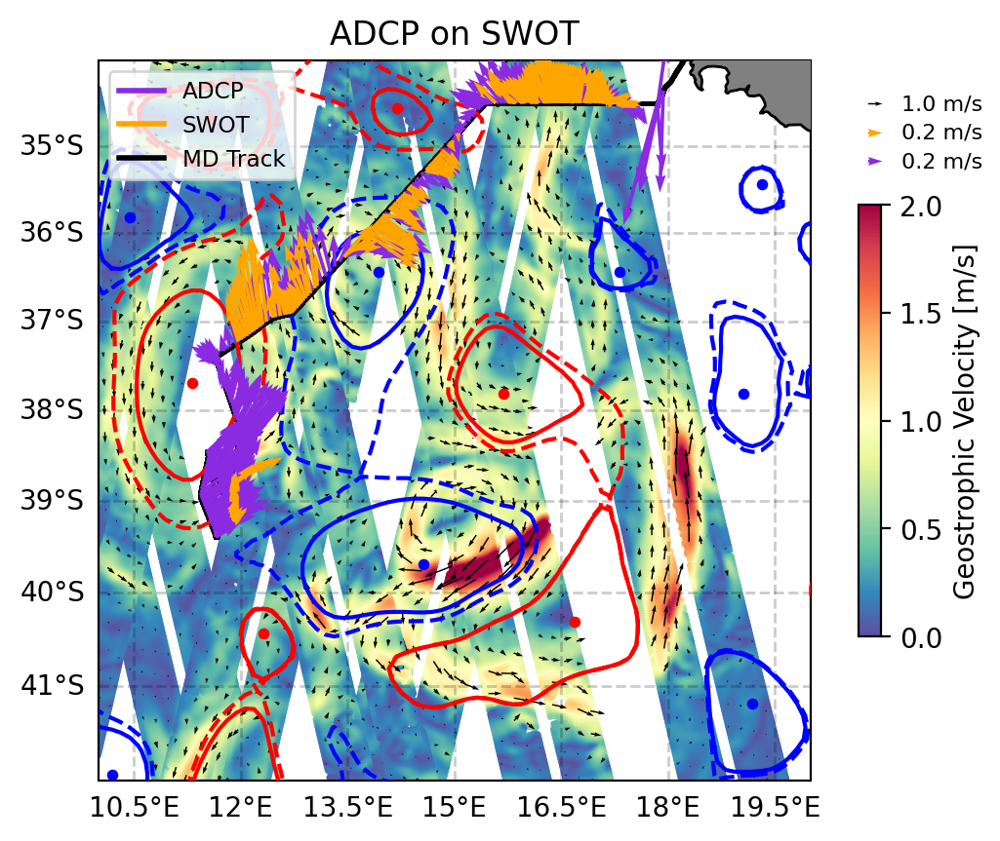

In [137]:
# -----------------------------
# PARAMÈTRES ZONE

lon_min, lon_max, lat_min, lat_max = 10, 16, -39.5, -34
pos_west,pos_east,pos_south,pos_north  = 10, 16, -39.5,-34  #Reset the area
ft=10

fig, ax = setup_map(extent, "ADCP on SWOT", proj, ft)

dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

adcp_cut = get_depth_mask(new_adcp)
lon_adcp = adcp_cut.lon_adcp.values
lat_adcp = adcp_cut.lat_adcp.values
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

# ax.scatter(
#     adcp_cut.lon_adcp.values[::50],
#     adcp_cut.lat_adcp.values[::50],
#     s=1,
#     color="black",
#     transform=crs,
#     zorder=15
# )

# lon = adcp_cut.lon_adcp.values
# lat = adcp_cut.lat_adcp.values

# # round to nearest 0.1 degree grid
# lon_bin = np.round(lon / deg) * deg
# lat_bin = np.round(lat / deg) * deg

# # keep only unique grid points
# mask = np.ones(lon.shape, dtype=bool)

# seen = set()

# for i in range(lon.size):
#     key = (lon_bin[i], lat_bin[i])
#     if key in seen:
#         mask[i] = False
#     else:
#         seen.add(key)

step_q = 10
q_adcp = ax.quiver(
    lon_adcp[::step_q],
    lat_adcp[::step_q],
    u_adcp[::step_q],
    v_adcp[::step_q],
    transform=crs,
    scale=10,
    width=0.005,
    color="blueviolet",
    zorder=100,
)

ax.scatter(
    longs_bato[::50],
    lat_bato[::50],
    s=0.5,
    color="black",
    transform=crs,
    zorder=10,
)

for ds_cut, ds_full in zip(tracks_cut, tracks):

    lon_swot = ds_cut.longitude.values
    lat_swot = ds_cut.latitude.values

    ugos_swot = ds_cut.ugos_filtered.values
    vgos_swot = ds_cut.vgos_filtered.values

    vel = np.sqrt(
        ugos_swot**2 + vgos_swot**2
    )

    sc = ax.scatter(
        lon_swot.flatten(),
        lat_swot.flatten(),
        c=vel,
        s=1,
        cmap="Spectral_r",
        vmin=0,
        vmax=2,
        transform=ccrs.PlateCarree()
    )

    # SWOT arrows
    step = 100
    q_swot_v = ax.quiver(
        lon_swot.flatten()[::step],
        lat_swot.flatten()[::step],
        ugos_swot.flatten()[::step],
        vgos_swot.flatten()[::step],
        color="black",
        scale=50,
        width=0.002,
        transform=ccrs.PlateCarree()
    )


    # interpolate SWOT velocity onto ship track
    ugos_track, vgos_track, dist_km = interpolate_swot(
        adcp_cut,
        ds_cut.ugos_filtered,
        ds_cut.vgos_filtered,
        ds_cut.longitude,
        ds_cut.latitude,
        max_dist_km=1)
    if np.all(np.isnan(ugos_track)):
        print("Skipping SWOT swath: too far from ADCP")
        continue
    step_q = 5
    q_swot = ax.quiver(
        lon_adcp[::step_q],
        lat_adcp[::step_q],
        ugos_track.values[::step_q],
        vgos_track.values[::step_q],
        transform=crs,
        scale=10,
        width=0.005,
        color="orange",
        zorder=100
    )
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label("Geostrophic Velocity [m/s]")

ax.quiverkey(
    q_adcp,
    X=1.1,
    Y=0.9,
    U=0.2,
    label="0.2 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color="orange"
)
ax.quiverkey(
    q_swot,
    X=1.1,
    Y=0.86,
    U=0.2,
    label="0.2 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color="blueviolet"
)
ax.quiverkey(
    q_swot_v,
    X=1.1,
    Y=0.94,
    U=1.0,
    label="1.0 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color = "black"
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="blueviolet",lw=2,label="ADCP"),
    Line2D([0],[0],color="orange",lw=2,label="SWOT"),
    Line2D([0],[0],color="black",lw=2,label="MD Track")
]


leg = ax.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100)

Skipping SWOT swath: too far from ADCP
Skipping SWOT swath: too far from ADCP


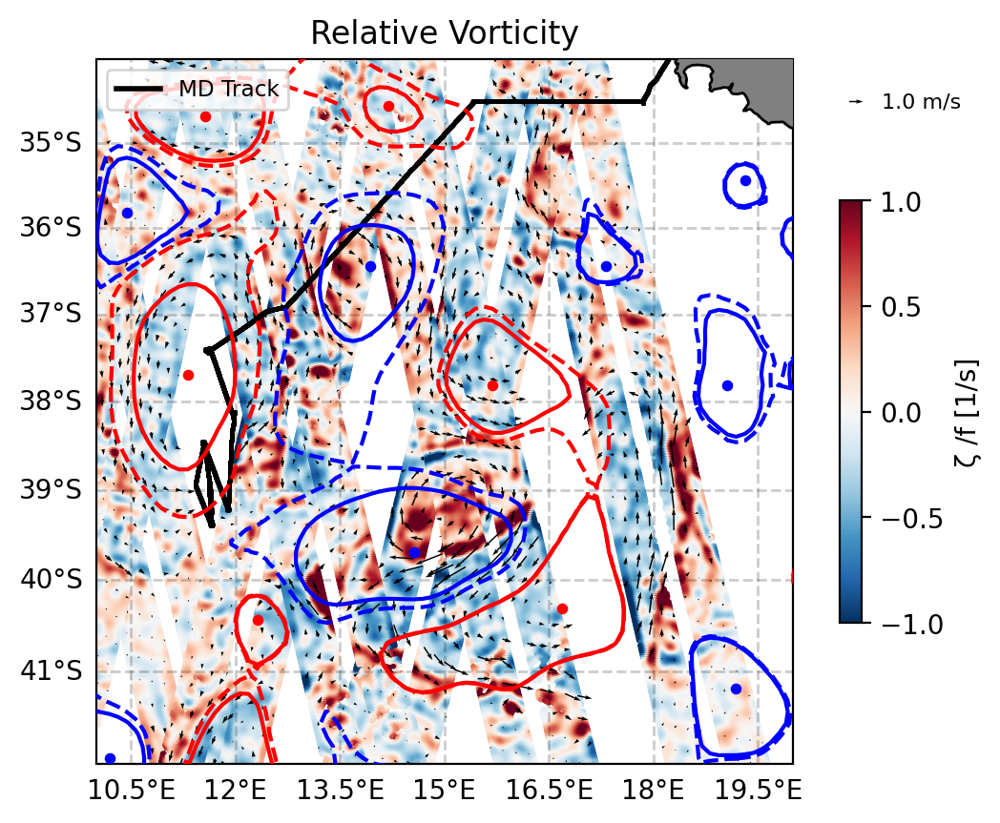

In [139]:

fig, ax = setup_map(extent, "Relative Vorticity", proj, ft)

dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

adcp_cut = get_depth_mask(new_adcp)
lon_adcp = adcp_cut.lon_adcp.values
lat_adcp = adcp_cut.lat_adcp.values
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

# step = 5
# q_adcp = ax.quiver(
#     lon_adcp[::step],
#     lat_adcp[::step],
#     u_adcp[::step],
#     v_adcp[::step],
#     transform=crs,
#     scale=5,
#     width=0.005,
#     color="blueviolet",
#     zorder=100,
# )

ax.scatter(
    longs_bato[::50],
    lat_bato[::50],
    s=0.5,
    color="black",
    transform=crs,
    zorder=10,
)

for ds_cut, ds_full in zip(tracks_cut, tracks):

    lon_swot = ds_cut.longitude.values
    lat_swot = ds_cut.latitude.values

    ugos_swot = ds_cut.ugos_filtered.values
    vgos_swot = ds_cut.vgos_filtered.values

    vel = np.sqrt(
        ugos_swot**2 + vgos_swot**2
    )
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    shear = shear_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    sc = ax.scatter(
        lon_swot.flatten(),
        lat_swot.flatten(),
        c=rel_vort/f0,
        s=1,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree()
    )

    # SWOT arrows
    step = 100
    q_swot_v = ax.quiver(
        lon_swot.flatten()[::step],
        lat_swot.flatten()[::step],
        ugos_swot.flatten()[::step],
        vgos_swot.flatten()[::step],
        color="black",
        scale=50,
        width=0.002,
        transform=ccrs.PlateCarree()
    )


    # interpolate SWOT velocity onto ship track
    ugos_track, vgos_track, dist_km = interpolate_swot(
        adcp_cut,
        ds_cut.ugos_filtered,
        ds_cut.vgos_filtered,
        ds_cut.longitude,
        ds_cut.latitude,
        max_dist_km=1)
    if np.all(np.isnan(ugos_track)):
        print("Skipping SWOT swath: too far from ADCP")
        continue
    # q_swot = ax.quiver(
    #     lon_adcp[::step_q],
    #     lat_adcp[::step_q],
    #     ugos_track.values[::step_q],
    #     vgos_track.values[::step_q],
    #     transform=crs,
    #     scale=5,
    #     width=0.005,
    #     color="green",
    #     zorder=100
    # )
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label("\u03B6 /f [1/s]")

# ax.quiverkey(
#     q_adcp,
#     X=1.1,
#     Y=0.9,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="green"
# )
# ax.quiverkey(
#     q_swot,
#     X=1.1,
#     Y=0.86,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="blueviolet"
# )
ax.quiverkey(
    q_swot_v,
    X=1.1,
    Y=0.94,
    U=1.0,
    label="1.0 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color = "black"
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="black",lw=2,label="MD Track")
]


leg = ax.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100)

Skipping SWOT swath: too far from ADCP
Skipping SWOT swath: too far from ADCP


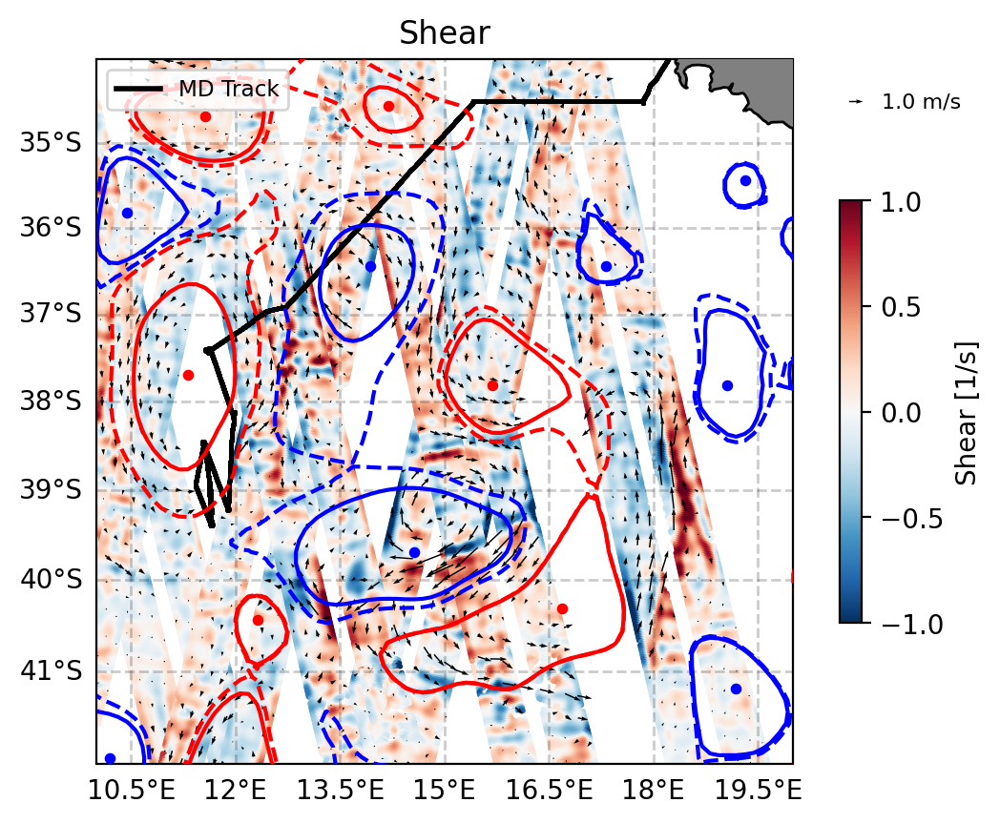

In [ ]:

fig, ax = setup_map(extent, "Shear", proj, ft)

dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

adcp_cut = get_depth_mask(new_adcp)
lon_adcp = adcp_cut.lon_adcp.values
lat_adcp = adcp_cut.lat_adcp.values
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

step = 5
# q_adcp = ax.quiver(
#     lon_adcp[::step],
#     lat_adcp[::step],
#     u_adcp[::step],
#     v_adcp[::step],
#     transform=crs,
#     scale=5,
#     width=0.005,
#     color="blueviolet",
#     zorder=100,
# )

ax.scatter(
    longs_bato[::50],
    lat_bato[::50],
    s=0.5,
    color="black",
    transform=crs,
    zorder=10,
)

for ds_cut, ds_full in zip(tracks_cut, tracks):

    lon_swot = ds_cut.longitude.values
    lat_swot = ds_cut.latitude.values

    ugos_swot = ds_cut.ugos_filtered.values
    vgos_swot = ds_cut.vgos_filtered.values

    vel = np.sqrt(
        ugos_swot**2 + vgos_swot**2
    )
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    shear = shear_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    sc = ax.scatter(
        lon_swot.flatten(),
        lat_swot.flatten(),
        c=shear/f0,
        s=1,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree()
    )

    # SWOT arrows
    step = 100
    q_swot_v = ax.quiver(
        lon_swot.flatten()[::step],
        lat_swot.flatten()[::step],
        ugos_swot.flatten()[::step],
        vgos_swot.flatten()[::step],
        color="black",
        scale=50,
        width=0.002,
        transform=ccrs.PlateCarree()
    )


    # interpolate SWOT velocity onto ship track
    ugos_track, vgos_track, dist_km = interpolate_swot(
        adcp_cut,
        ds_cut.ugos_filtered,
        ds_cut.vgos_filtered,
        ds_cut.longitude,
        ds_cut.latitude,
        max_dist_km=1)
    
    if np.all(np.isnan(ugos_track)):
        print("Skipping SWOT swath: too far from ADCP")
        continue
    # q_swot = ax.quiver(
    #     lon_adcp[::step_q],
    #     lat_adcp[::step_q],
    #     ugos_track.values[::step_q],
    #     vgos_track.values[::step_q],
    #     transform=crs,
    #     scale=5,
    #     width=0.005,
    #     color="green",
    #     zorder=100
    # )
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label("Shear [1/s]")

# ax.quiverkey(
#     q_adcp,
#     X=1.1,
#     Y=0.9,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="green"
# )
# ax.quiverkey(
#     q_swot,
#     X=1.1,
#     Y=0.86,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="blueviolet"
# )
ax.quiverkey(
    q_swot_v,
    X=1.1,
    Y=0.94,
    U=1.0,
    label="1.0 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color = "black"
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="black",lw=2,label="MD Track")
]


leg = ax.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100)

Skipping SWOT swath: too far from ADCP
Skipping SWOT swath: too far from ADCP


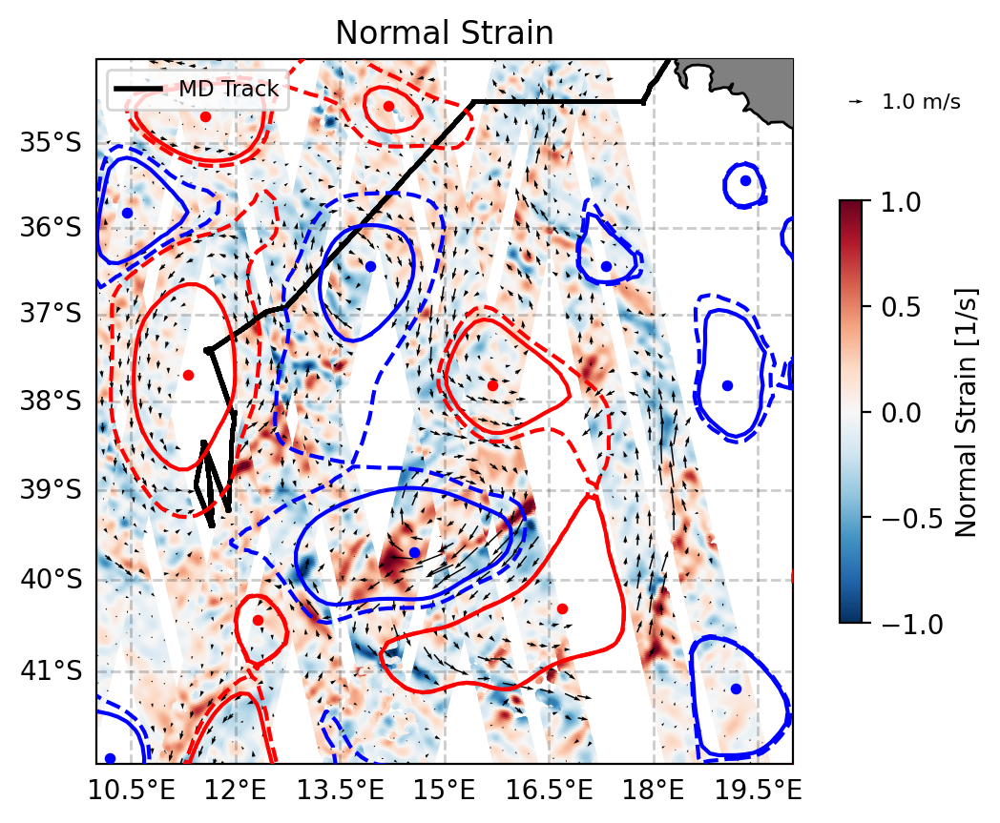

In [141]:


fig, ax = setup_map(extent, "Normal Strain", proj, ft)

dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

adcp_cut = get_depth_mask(new_adcp)
lon_adcp = adcp_cut.lon_adcp.values
lat_adcp = adcp_cut.lat_adcp.values
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

# step = 5
# q_adcp = ax.quiver(
#     lon_adcp[::step],
#     lat_adcp[::step],
#     u_adcp[::step],
#     v_adcp[::step],
#     transform=crs,
#     scale=5,
#     width=0.005,
#     color="blueviolet",
#     zorder=100,
# )

ax.scatter(
    longs_bato[::50],
    lat_bato[::50],
    s=0.5,
    color="black",
    transform=crs,
    zorder=10,
)

for ds_cut, ds_full in zip(tracks_cut, tracks):

    lon_swot = ds_cut.longitude.values
    lat_swot = ds_cut.latitude.values

    ugos_swot = ds_cut.ugos_filtered.values
    vgos_swot = ds_cut.vgos_filtered.values

    vel = np.sqrt(
        ugos_swot**2 + vgos_swot**2
    )
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    shear = shear_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    sc = ax.scatter(
        lon_swot.flatten(),
        lat_swot.flatten(),
        c=normal_strain/f0,
        s=1,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree()
    )

    # SWOT arrows
    step = 100
    q_swot_v = ax.quiver(
        lon_swot.flatten()[::step],
        lat_swot.flatten()[::step],
        ugos_swot.flatten()[::step],
        vgos_swot.flatten()[::step],
        color="black",
        scale=50,
        width=0.002,
        transform=ccrs.PlateCarree()
    )


    # interpolate SWOT velocity onto ship track
    ugos_track, vgos_track, dist_km = interpolate_swot(
        adcp_cut,
        ds_cut.ugos_filtered,
        ds_cut.vgos_filtered,
        ds_cut.longitude,
        ds_cut.latitude,
        max_dist_km=1)
    if np.all(np.isnan(ugos_track)):
        print("Skipping SWOT swath: too far from ADCP")
        continue
    # q_swot = ax.quiver(
    #     lon_adcp[::step_q],
    #     lat_adcp[::step_q],
    #     ugos_track.values[::step_q],
    #     vgos_track.values[::step_q],
    #     transform=crs,
    #     scale=5,
    #     width=0.005,
    #     color="green",
    #     zorder=100
    # )
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label("Normal Strain [1/s]")

# ax.quiverkey(
#     q_adcp,
#     X=1.1,
#     Y=0.9,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="green"
# )
# ax.quiverkey(
#     q_swot,
#     X=1.1,
#     Y=0.86,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="blueviolet"
# )
ax.quiverkey(
    q_swot_v,
    X=1.1,
    Y=0.94,
    U=1.0,
    label="1.0 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color = "black"
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="black",lw=2,label="MD Track")
]


leg = ax.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100)

In [143]:
##### Load Eddies #####
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

Skipping SWOT swath: too far from ADCP
Skipping SWOT swath: too far from ADCP


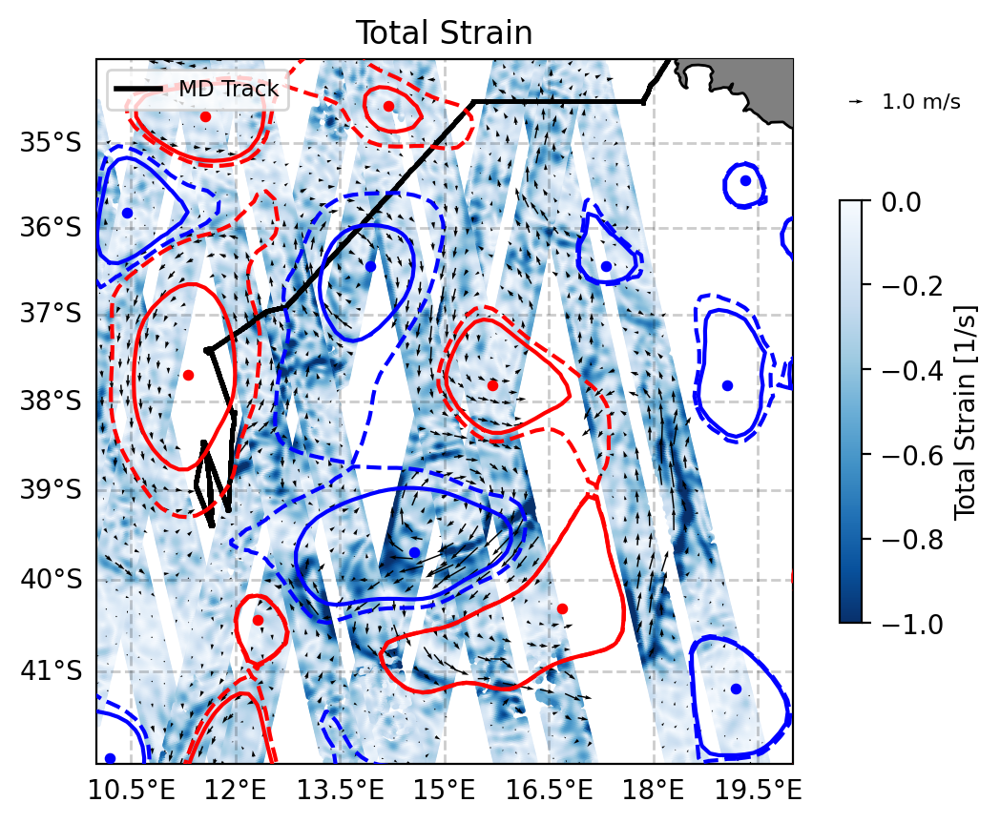

In [142]:
# -----------------------------
# PARAMÈTRES ZONE
# -----------------------------
ft=10

fig, ax = setup_map(extent, "Total Strain", proj, ft)

dir_eddies = dir + f"Eddies/{date}/{date}_toeddies/"
files = os.listdir(dir_eddies)
anti, cyc = load_eddies(dir_eddies)

plot_eddies(ax, anti, "red", crs)
plot_eddies(ax, cyc, "blue", crs)

adcp_cut = get_depth_mask(new_adcp)
lon_adcp = adcp_cut.lon_adcp.values
lat_adcp = adcp_cut.lat_adcp.values
u_adcp, v_adcp = average_adcp_velocity(adcp_cut)
adcp_mag = velocity_magnitude(adcp_cut.uvel_adcp.values, adcp_cut.vvel_adcp.values)

x_dist = along_track_distance(
    adcp_cut.lon_adcp.values,
    adcp_cut.lat_adcp.values
)

# step = 5
# q_adcp = ax.quiver(
#     lon_adcp[::step],
#     lat_adcp[::step],
#     u_adcp[::step],
#     v_adcp[::step],
#     transform=crs,
#     scale=5,
#     width=0.005,
#     color="blueviolet",
#     zorder=100,
# )

ax.scatter(
    longs_bato[::50],
    lat_bato[::50],
    s=0.5,
    color="black",
    transform=crs,
    zorder=10,
)

for ds_cut, ds_full in zip(tracks_cut, tracks):

    lon_swot = ds_cut.longitude.values
    lat_swot = ds_cut.latitude.values

    ugos_swot = ds_cut.ugos_filtered.values
    vgos_swot = ds_cut.vgos_filtered.values

    vel = np.sqrt(
        ugos_swot**2 + vgos_swot**2
    )
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    shear = shear_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered.values, ds_cut.vgos_filtered.values,lon_swot,lat_swot)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    sc = ax.scatter(
        lon_swot.flatten(),
        lat_swot.flatten(),
        c=np.sqrt(tot_strain**2)/f0,
        s=1,
        cmap="Blues_r",
        vmin=-1,
        vmax=0,
        transform=ccrs.PlateCarree()
    )

    # SWOT arrows
    step = 100
    q_swot_v = ax.quiver(
        lon_swot.flatten()[::step],
        lat_swot.flatten()[::step],
        ugos_swot.flatten()[::step],
        vgos_swot.flatten()[::step],
        color="black",
        scale=50,
        width=0.002,
        transform=ccrs.PlateCarree()
    )


    # interpolate SWOT velocity onto ship track
    ugos_track, vgos_track, dist_km = interpolate_swot(
        adcp_cut,
        ds_cut.ugos_filtered,
        ds_cut.vgos_filtered,
        ds_cut.longitude,
        ds_cut.latitude,
        max_dist_km=1)
    if np.all(np.isnan(ugos_track)):
        print("Skipping SWOT swath: too far from ADCP")
        continue
    # q_swot = ax.quiver(
    #     lon_adcp[::step_q],
    #     lat_adcp[::step_q],
    #     ugos_track.values[::step_q],
    #     vgos_track.values[::step_q],
    #     transform=crs,
    #     scale=5,
    #     width=0.005,
    #     color="green",
    #     zorder=100
    # )
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label("Total Strain [1/s]")

# ax.quiverkey(
#     q_adcp,
#     X=1.1,
#     Y=0.9,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="green"
# )
# ax.quiverkey(
#     q_swot,
#     X=1.1,
#     Y=0.86,
#     U=0.2,
#     label="0.2 m/s",
#     fontproperties={"size": 8},
#     labelpos="E",
#     color="blueviolet"
# )
ax.quiverkey(
    q_swot_v,
    X=1.1,
    Y=0.94,
    U=1.0,
    label="1.0 m/s",
    fontproperties={"size": 8},
    labelpos="E",
    color = "black"
)
from matplotlib.lines import Line2D

legend_handles = [
    Line2D([0],[0],color="black",lw=2,label="MD Track")
]


leg = ax.legend(
    handles=legend_handles,
    loc="upper left", fontsize="small"
)
leg.set_zorder(100)

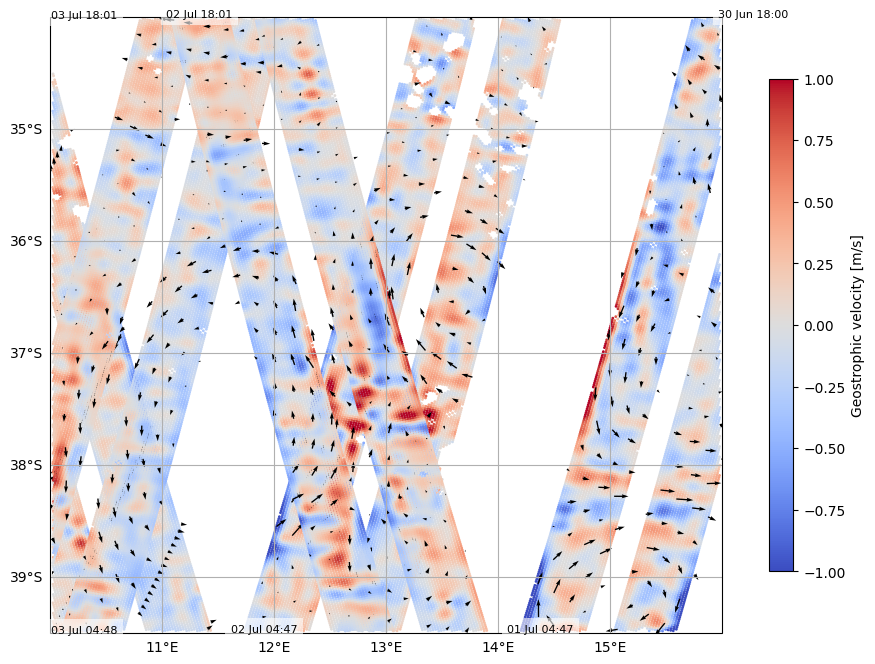

In [104]:
# -----------------------------
# PARAMÈTRES ZONE
# -----------------------------
# lon_min, lon_max = 6, 24
# lat_min, lat_max = -43, -33
lon_min, lon_max, lat_min, lat_max = 10, 16, -39.5, -34
pos_west,pos_east,pos_south,pos_north  = 10, 16, -39.5,-34  #Reset the area

# -----------------------------
# FIGURE
# -----------------------------
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# -----------------------------
# ZOOM
# -----------------------------
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# -----------------------------
# LOOP TRACKS
# -----------------------------
for ds_cut, ds_full in zip(tracks_cut, tracks):

    # ---- coordonnées
    lon = ds_cut.longitude.values
    lat = ds_cut.latitude.values

    # ---- vitesse
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    shear = shear_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    # calc the strain etc
    f0 = coriolis_parameter((lat_min + lat_max)/2)

    sc = ax.scatter(
        lon.flatten(),
        lat.flatten(),
        c=shear/f0,
        s=1,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree()
    )

    step = 100
    vecteurs = ax.quiver(
        lon.flatten()[::step],
        lat.flatten()[::step],
        ugos[::step],
        vgos[::step],
        color="black",
        scale=5.e1,
        width=0.002,
        transform=ccrs.PlateCarree()
    )

    # -----------------------------
    # DATE (PROPRE, SANS IDX)
    # -----------------------------
    t = pd.to_datetime(ds_cut.time.values)
    t_valid = t[~pd.isna(t)]
    first_time = t_valid[0]
    first_time = first_time.strftime("%d %b %H:%M")

    # t = pd.to_datetime(ds_full.time.values)
    # t = t[~pd.isna(t)]

    # date_str = t[0].strftime("%d %b")
    # start_time = t[0].strftime("%H:%M")

    # -----------------------------
    # POSITION DEBUT TRACK (ZONE)
    # -----------------------------
    mask = (
        (ds_full.longitude.values >= lon_min) &
        (ds_full.longitude.values <= lon_max) &
        (ds_full.latitude.values >= lat_min) &
        (ds_full.latitude.values <= lat_max)
    )

    idx = np.where(mask.flatten())[0]

    if len(idx) > 0:
        i0 = idx[0]

        x0 = ds_full.longitude.values.flatten()[i0]
        y0 = ds_full.latitude.values.flatten()[i0]

        ax.text(
            x0, y0,
            f"{first_time}",
            fontsize=8,
            color="black",
            transform=ccrs.PlateCarree(),
            bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
        )

# -----------------------------
# SHIP
# -----------------------------
# ax.scatter(
#     ship_lon_st_22,
#     ship_lat_st_22,
#     color="black",
#     s=120,
#     marker="x",
#     transform=ccrs.PlateCarree()
# )

# ax.text(
#     ship_lon_st_22 - 0.2,
#     ship_lat_st_22 + 0.2,
#     "ST-22",
#     fontsize=10,
#     color="black",
#     transform=ccrs.PlateCarree()
# )

# -----------------------------
# GRID
# -----------------------------
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# -----------------------------
# COLORBAR (COMMUNE)
# -----------------------------
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Geostrophic velocity [m/s]")

# -----------------------------
# TITLE
# -----------------------------
# ax.set_title("SWOT L3 (subset + correct time labels)")

plt.show()

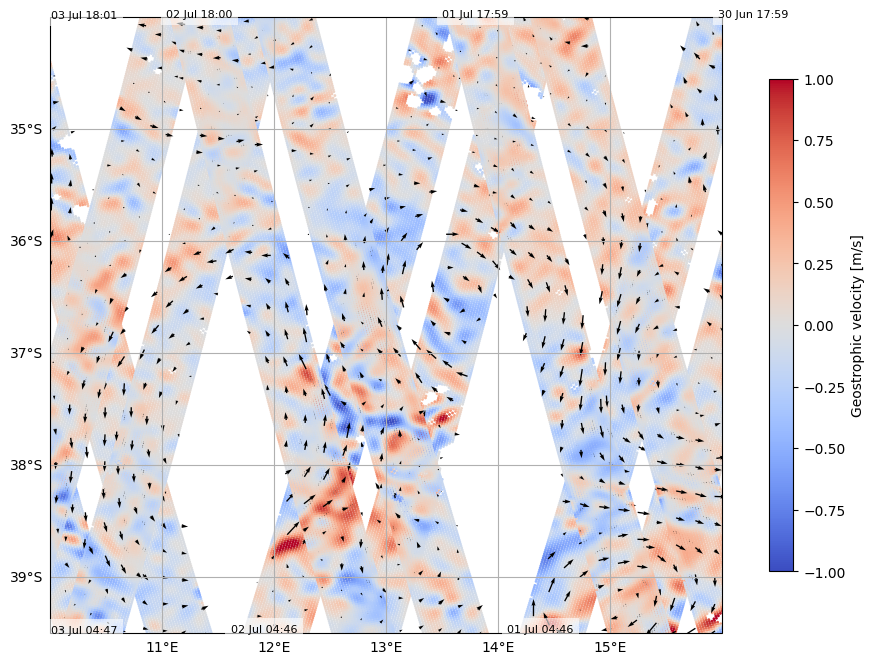

In [ ]:
# -----------------------------
# PARAMÈTRES ZONE
# -----------------------------
# lon_min, lon_max = 6, 24
# lat_min, lat_max = -43, -33
lon_min, lon_max, lat_min, lat_max = 10, 16, -39.5, -34
pos_west,pos_east,pos_south,pos_north  = 10, 16, -39.5,-34  #Reset the area

# -----------------------------
# FIGURE
# -----------------------------
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# -----------------------------
# ZOOM
# -----------------------------
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# -----------------------------
# LOOP TRACKS
# -----------------------------
for ds_cut, ds_full in zip(tracks_cut, tracks):

    # ---- coordonnées
    lon = ds_cut.longitude.values
    lat = ds_cut.latitude.values

    # ---- vitesse
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    shear = shear_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    # calc the strain etc
    f0 = coriolis_parameter((lat_min + lat_max)/2)

    sc = ax.scatter(
        lon.flatten(),
        lat.flatten(),
        c=normal_strain/f0,
        s=1,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ccrs.PlateCarree()
    )

    step = 100
    vecteurs = ax.quiver(
        lon.flatten()[::step],
        lat.flatten()[::step],
        ugos[::step],
        vgos[::step],
        color="black",
        scale=5.e1,
        width=0.002,
        transform=ccrs.PlateCarree()
    )

    # -----------------------------
    # DATE (PROPRE, SANS IDX)
    # -----------------------------
    t = pd.to_datetime(ds_cut.time.values)
    t_valid = t[~pd.isna(t)]
    first_time = t_valid[0]
    first_time = first_time.strftime("%d %b %H:%M")

    # t = pd.to_datetime(ds_full.time.values)
    # t = t[~pd.isna(t)]

    # date_str = t[0].strftime("%d %b")
    # start_time = t[0].strftime("%H:%M")

    # -----------------------------
    # POSITION DEBUT TRACK (ZONE)
    # -----------------------------
    mask = (
        (ds_full.longitude.values >= lon_min) &
        (ds_full.longitude.values <= lon_max) &
        (ds_full.latitude.values >= lat_min) &
        (ds_full.latitude.values <= lat_max)
    )

    idx = np.where(mask.flatten())[0]

    if len(idx) > 0:
        i0 = idx[0]

        x0 = ds_full.longitude.values.flatten()[i0]
        y0 = ds_full.latitude.values.flatten()[i0]

        ax.text(
            x0, y0,
            f"{first_time}",
            fontsize=8,
            color="black",
            transform=ccrs.PlateCarree(),
            bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
        )

# -----------------------------
# SHIP
# -----------------------------
# ax.scatter(
#     ship_lon_st_22,
#     ship_lat_st_22,
#     color="black",
#     s=120,
#     marker="x",
#     transform=ccrs.PlateCarree()
# )

# ax.text(
#     ship_lon_st_22 - 0.2,
#     ship_lat_st_22 + 0.2,
#     "ST-22",
#     fontsize=10,
#     color="black",
#     transform=ccrs.PlateCarree()
# )

# -----------------------------
# GRID
# -----------------------------
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# -----------------------------
# COLORBAR (COMMUNE)
# -----------------------------
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Geostrophic velocity [m/s]")

# -----------------------------
# TITLE
# -----------------------------
# ax.set_title("SWOT L3 (subset + correct time labels)")

plt.show()

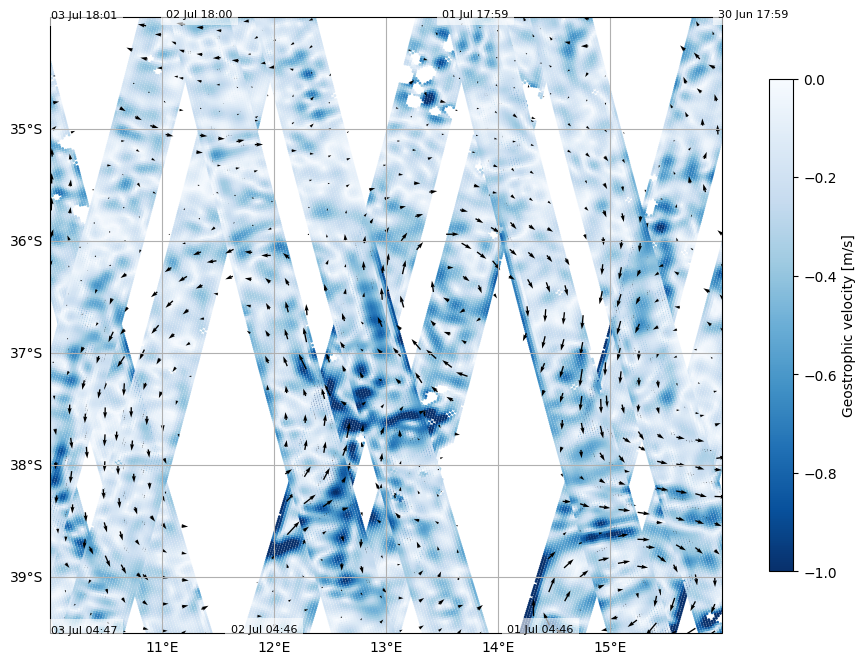

In [ ]:
# -----------------------------
# PARAMÈTRES ZONE
# -----------------------------
# lon_min, lon_max = 6, 24
# lat_min, lat_max = -43, -33
lon_min, lon_max, lat_min, lat_max = 10, 16, -39.5, -34
pos_west,pos_east,pos_south,pos_north  = 10, 16, -39.5,-34  #Reset the area
# -----------------------------
# FIGURE
# -----------------------------
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# -----------------------------
# ZOOM
# -----------------------------
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# -----------------------------
# LOOP TRACKS
# -----------------------------
for ds_cut, ds_full in zip(tracks_cut, tracks):

    # ---- coordonnées
    lon = ds_cut.longitude.values
    lat = ds_cut.latitude.values

    # ---- vitesse
    ugos = ds_cut.ugos_filtered.values.flatten()
    vgos = ds_cut.vgos_filtered.values.flatten()
    rel_vort = relative_vorticity_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    shear = shear_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    normal_strain  = normal_strain_from_uv(ds_cut.ugos_filtered, ds_cut.vgos_filtered.values,lon,lat)
    tot_strain = np.sqrt(normal_strain**2 + shear**2)

    vel = np.sqrt(ugos**2 + vgos**2)

    # calc the strain etc
    f0 = coriolis_parameter((lat_min + lat_max)/2)

    sc = ax.scatter(
        lon.flatten(),
        lat.flatten(),
        c=tot_strain/f0,
        s=1,
        cmap="Blues_r",
        vmin=-1,
        vmax=0,
        transform=ccrs.PlateCarree()
    )

    step = 100
    vecteurs = ax.quiver(
        lon.flatten()[::step],
        lat.flatten()[::step],
        ugos[::step],
        vgos[::step],
        color="black",
        scale=5.e1,
        width=0.002,
        transform=ccrs.PlateCarree()
    )

    # -----------------------------
    # DATE (PROPRE, SANS IDX)
    # -----------------------------
    t = pd.to_datetime(ds_cut.time.values)
    t_valid = t[~pd.isna(t)]
    first_time = t_valid[0]
    first_time = first_time.strftime("%d %b %H:%M")

    # t = pd.to_datetime(ds_full.time.values)
    # t = t[~pd.isna(t)]

    # date_str = t[0].strftime("%d %b")
    # start_time = t[0].strftime("%H:%M")

    # -----------------------------
    # POSITION DEBUT TRACK (ZONE)
    # -----------------------------
    mask = (
        (ds_full.longitude.values >= lon_min) &
        (ds_full.longitude.values <= lon_max) &
        (ds_full.latitude.values >= lat_min) &
        (ds_full.latitude.values <= lat_max)
    )

    idx = np.where(mask.flatten())[0]

    if len(idx) > 0:
        i0 = idx[0]

        x0 = ds_full.longitude.values.flatten()[i0]
        y0 = ds_full.latitude.values.flatten()[i0]

        ax.text(
            x0, y0,
            f"{first_time}",
            fontsize=8,
            color="black",
            transform=ccrs.PlateCarree(),
            bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
        )

# -----------------------------
# SHIP
# -----------------------------
# ax.scatter(
#     ship_lon_st_22,
#     ship_lat_st_22,
#     color="black",
#     s=120,
#     marker="x",
#     transform=ccrs.PlateCarree()
# )

# ax.text(
#     ship_lon_st_22 - 0.2,
#     ship_lat_st_22 + 0.2,
#     "ST-22",
#     fontsize=10,
#     color="black",
#     transform=ccrs.PlateCarree()
# )

# -----------------------------
# GRID
# -----------------------------
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# -----------------------------
# COLORBAR (COMMUNE)
# -----------------------------
cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
cbar.set_label("Geostrophic velocity [m/s]")

# -----------------------------
# TITLE
# -----------------------------
# ax.set_title("SWOT L3 (subset + correct time labels)")

plt.show()

# MVP

In [2]:
mvp_ox = xr.open_dataset('data/MVP/section_2_3_OX.nc')
mvp_sal = xr.open_dataset('data/MVP/section_2_3_SAL.nc')
mvp_suna = xr.open_dataset('data/MVP/section_2_3_SUNA.nc')
mvp_temp = xr.open_dataset('data/MVP/section_2_3_TEMP.nc')

In [3]:
dates = mdates.num2date(mvp_ox.date)

In [4]:
def add_time_axis(ax, ds):
    ax_time = ax.twiny()

    # déplacer l’axe en bas
    ax_time.xaxis.set_label_position('bottom')
    ax_time.xaxis.tick_bottom()
    ax_time.spines['bottom'].set_position(('outward', 40))

    # conversion dates matplotlib → datetime
    time = mdates.num2date(ds.date.values)

    ax_time.set_xlim(time[0], time[-1])
    ax_time.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d-%H'))

    ax_time.set_xlabel("Time")
    ax_time.tick_params(axis='x', rotation=45)

    return ax_time

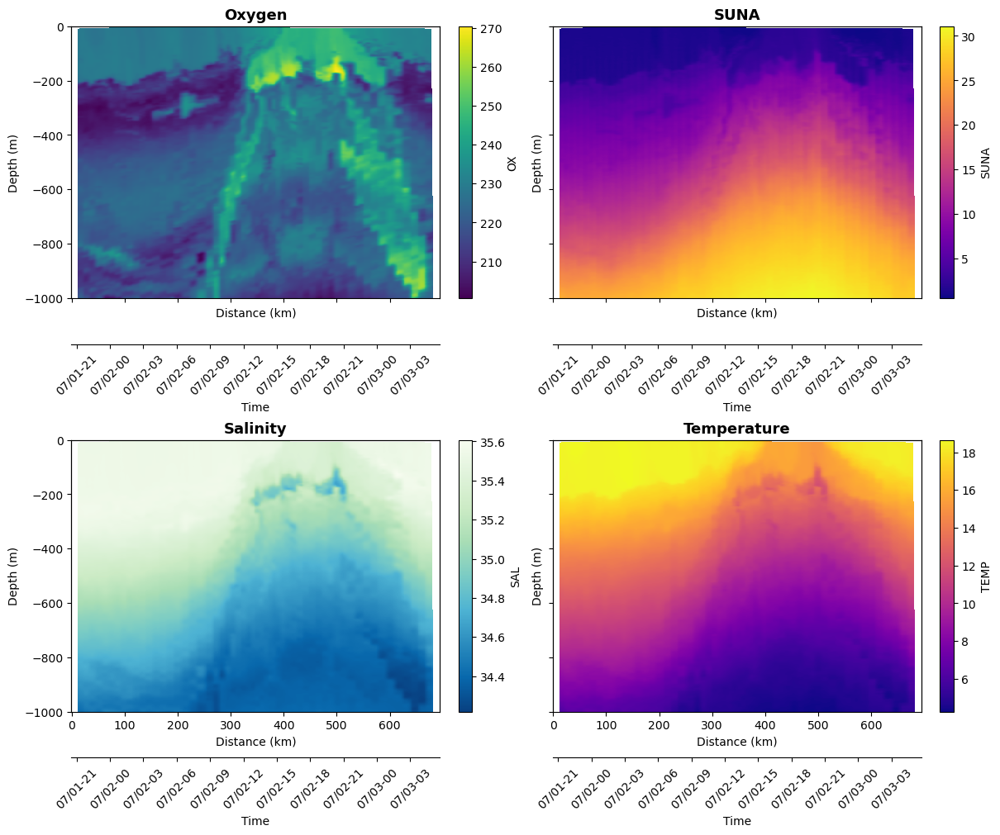

In [5]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox,   "OX",   "Oxygen",      "viridis"),
    (mvp_suna, "SUNA", "SUNA",        "plasma"),
    (mvp_sal,  "SAL",  "Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, "TEMP", "Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        ds[var],
        shading="auto",
        cmap=cmap
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(var)

    add_time_axis(axi, ds)
    

plt.show()

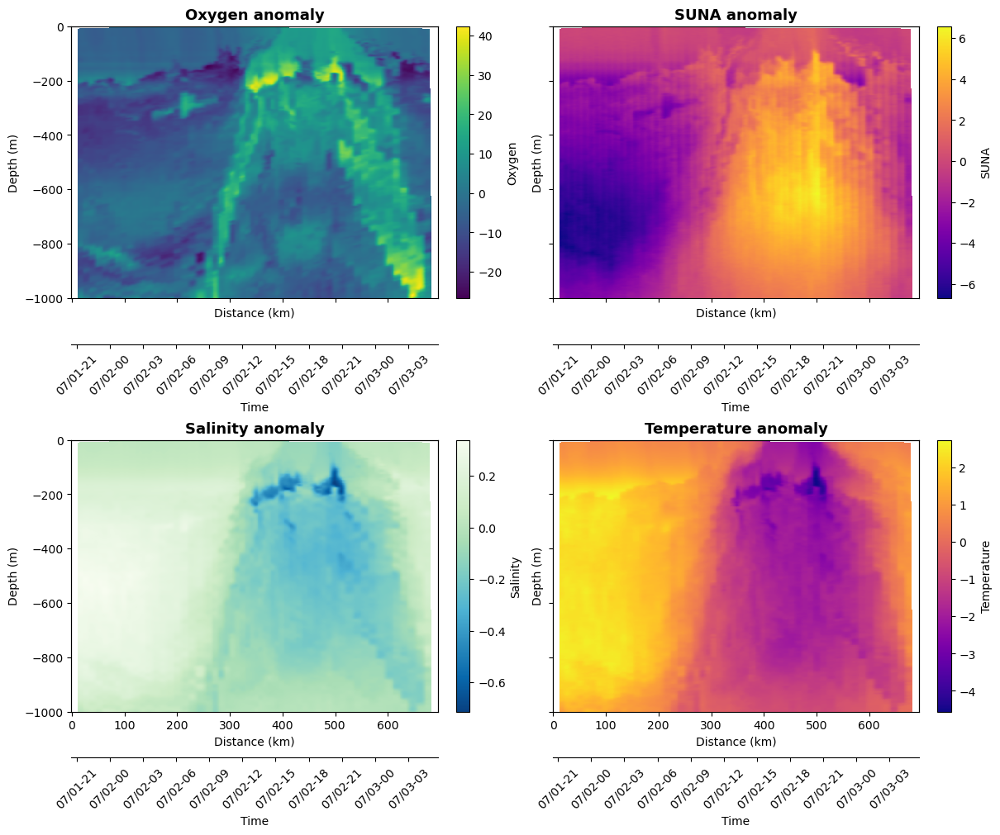

In [6]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(12, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, mvp_ox.OX - mvp_ox.OX.mean(dim="distance", skipna=True),   "Oxygen",      "viridis"),
    (mvp_suna, mvp_suna.SUNA - mvp_suna.SUNA.mean(dim="distance", skipna=True), "SUNA",        "plasma"),
    (mvp_sal, mvp_sal.SAL - mvp_sal.SAL.mean(dim="distance", skipna=True),  "Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, mvp_temp.TEMP - mvp_temp.TEMP.mean(dim="distance", skipna=True), "Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap
    )

    # axi.invert_yaxis()

    axi.set_title(title + ' anomaly', fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)
    

plt.show()

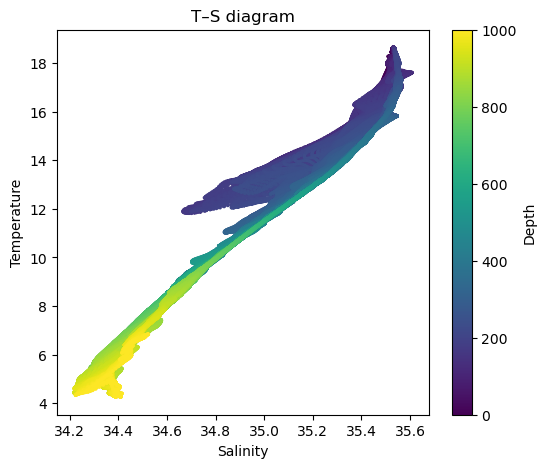

In [7]:
T = mvp_temp.TEMP.values
S = mvp_sal.SAL.values
Z = mvp_temp.depth.values[:, None]  # broadcast 2D

plt.figure(figsize=(6,5))

sc = plt.scatter(
    S.ravel(),
    T.ravel(),
    c=np.repeat(mvp_temp.depth.values, mvp_temp.distance.size),
    cmap="viridis",
    s=2
)

# plt.gca().invert_yaxis()
plt.colorbar(label="Depth")
plt.xlabel("Salinity")
plt.ylabel("Temperature")
plt.title("T–S diagram")
plt.show()

In [8]:
z = mvp_temp.depth.values

dT_dz = np.gradient(mvp_temp.TEMP.values, z, axis=0)
dS_dz = np.gradient(mvp_sal.SAL.values, z, axis=0)
dO2_dz = np.gradient(mvp_ox.OX.values, z, axis=0)
dNO3_dz = np.gradient(mvp_suna.SUNA.values, z, axis=0)

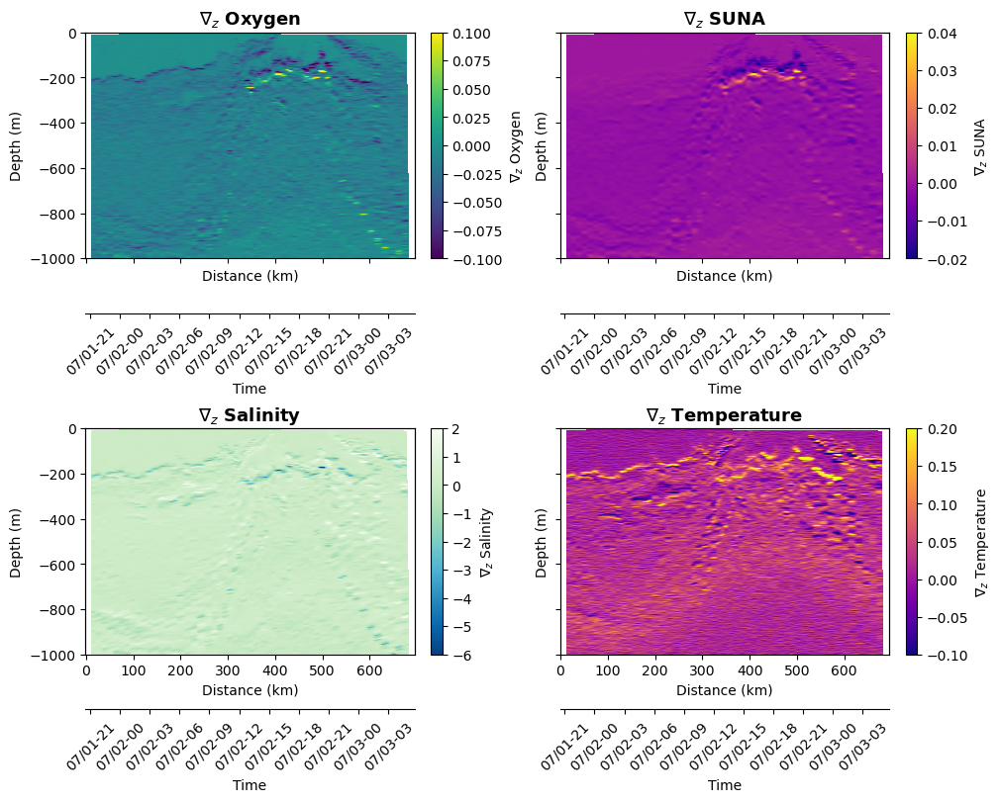

In [20]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, dT_dz,   r"$\nabla_z$ Oxygen",      "viridis", -0.1, 0.1),
    (mvp_suna, dS_dz, r"$\nabla_z$ SUNA",        "plasma", -0.02, 0.04),
    (mvp_sal, dO2_dz,  r"$\nabla_z$ Salinity",    "GnBu_r", -6, 2),   # si cmocean est installé
    (mvp_temp, dNO3_dz, r"$\nabla_z$ Temperature", "plasma", -0.1, 0.2)   # si cmocean est installé
]

for axi, (ds, var, title, cmap, vmin, vmax) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap,
        vmin=vmin, vmax=vmax,
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)

plt.show()

In [21]:
x = mvp_temp.distance.values

dT_dx = np.gradient(mvp_temp.TEMP.values, x, axis=1)
dS_dx = np.gradient(mvp_sal.SAL.values, x, axis=1)
dO2_dx = np.gradient(mvp_ox.OX.values, x, axis=1)
dNO3_dx = np.gradient(mvp_suna.SUNA.values, x, axis=1)

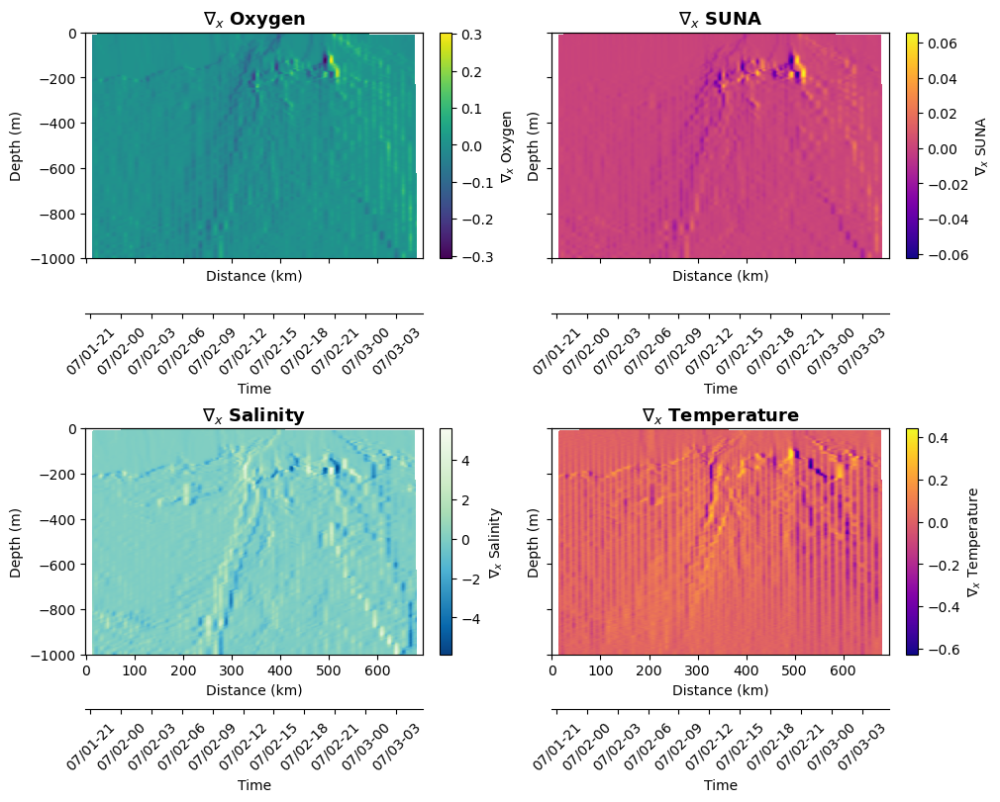

In [22]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(10, 8),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

plots = [
    (mvp_ox, dT_dx,   r"$\nabla_x$ Oxygen",      "viridis"),
    (mvp_suna, dS_dx, r"$\nabla_x$ SUNA",        "plasma"),
    (mvp_sal, dO2_dx,  r"$\nabla_x$ Salinity",    "GnBu_r"),   # si cmocean est installé
    (mvp_temp, dNO3_dx, r"$\nabla_x$ Temperature", "plasma")   # si cmocean est installé
]

for axi, (ds, var, title, cmap) in zip(ax.flat, plots):

    pcm = axi.pcolormesh(
        ds.distance,
        -ds.depth,
        var,
        shading="auto",
        cmap=cmap,
    )

    # axi.invert_yaxis()

    axi.set_title(title, fontsize=13, fontweight="bold")
    axi.set_xlabel("Distance (km)")
    axi.set_ylabel("Depth (m)")

    cbar = fig.colorbar(pcm, ax=axi)
    cbar.set_label(title)

    add_time_axis(axi, ds)

plt.show()

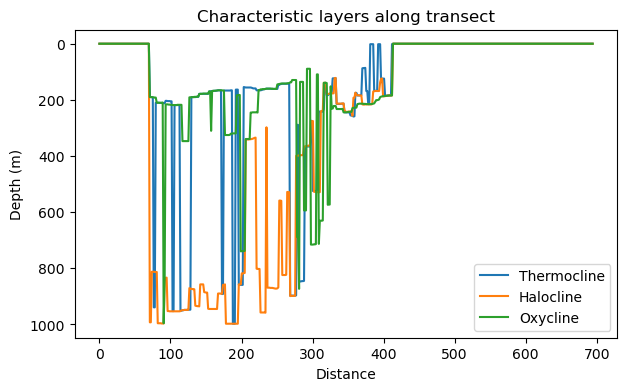

In [10]:
thermocline = np.argmax(np.abs(dT_dz), axis=0)
halocline = np.argmax(np.abs(dS_dz), axis=0)
oxycline = np.argmax(np.abs(dO2_dz), axis=0)

plt.figure(figsize=(7,4))

plt.plot(mvp_temp.distance, z[thermocline], label="Thermocline")
plt.plot(mvp_temp.distance, z[halocline], label="Halocline")
plt.plot(mvp_temp.distance, z[oxycline], label="Oxycline")

plt.gca().invert_yaxis()
plt.xlabel("Distance")
plt.ylabel("Depth (m)")
plt.legend()
plt.title("Characteristic layers along transect")
plt.show()

In [ ]:
lat = mvp_ox.lat

# -----------------------------
# 1. DEPTH -> PRESSURE
# -----------------------------
p = gsw.p_from_z(-mvp_ox.depth, lat)  # (depth,)

# -----------------------------
# 2. TEOS-10 DENSITY
# -----------------------------
lon = mvp_ox.lon
# p_2D = xr.DataArray(
#     p,
#     dims=mvp_temp.TEMP.dims,
#     coords=mvp_temp.TEMP.coords
# )

SA = gsw.SA_from_SP(mvp_sal.SAL, p, mvp_sal.lon, mvp_sal.lat)
CT = gsw.CT_from_t(SA, mvp_temp.TEMP.values, p)
rho = gsw.rho(SA, CT, p)  # (time, depth, lon)


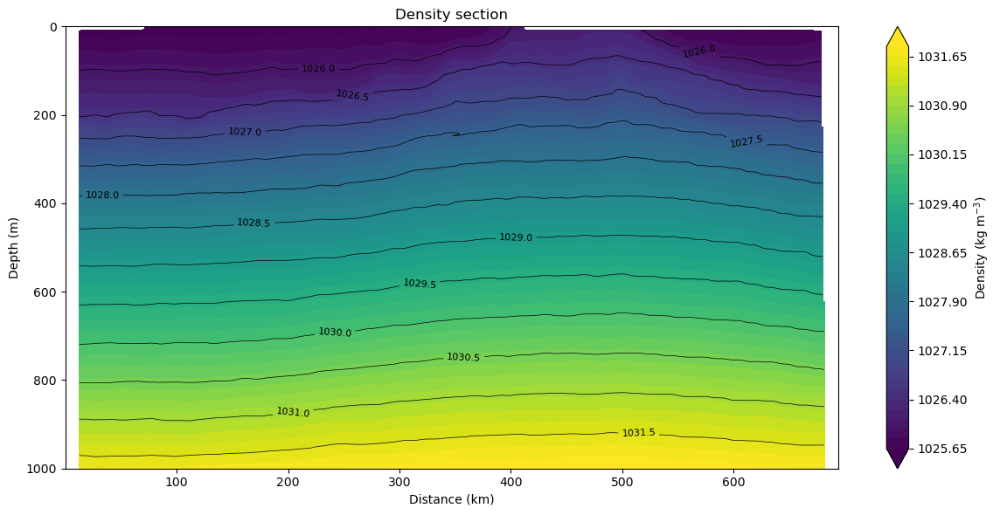

In [55]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    rho.distance,
    rho.depth,
    rho,
    levels=50,
    cmap="viridis",
    extend="both"
)

# Isopycnes
cs = ax.contour(
    rho.distance,
    rho.depth,
    rho,
    levels=np.arange(np.floor(rho.min()), np.ceil(rho.max()), 0.5),
    colors="k",
    linewidths=0.5
)

ax.clabel(cs, fmt="%.1f", fontsize=8)

cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()

In [ ]:
SA = gsw.SA_from_SP(mvp_sal.SAL, p, mvp_sal.lon, mvp_sal.lat)
CT = gsw.CT_from_t(SA, mvp_temp.TEMP.values, p)
sigma0 = gsw.sigma0(SA, CT)

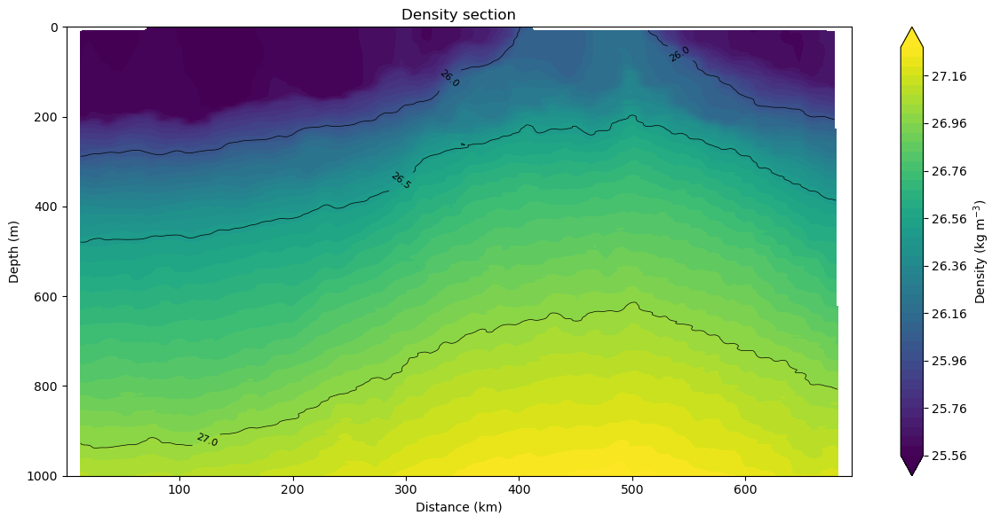

In [52]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    sigma0.distance,
    sigma0.depth,
    sigma0,
    levels=50,
    cmap="viridis",
    extend="both"
)

# Isopycnes
cs = ax.contour(
    sigma0.distance,
    sigma0.depth,
    sigma0,
    levels=np.arange(np.floor(sigma0.min()), np.ceil(sigma0.max()), 0.5),
    colors="k",
    linewidths=0.5
)

ax.clabel(cs, fmt="%.1f", fontsize=8)

cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()

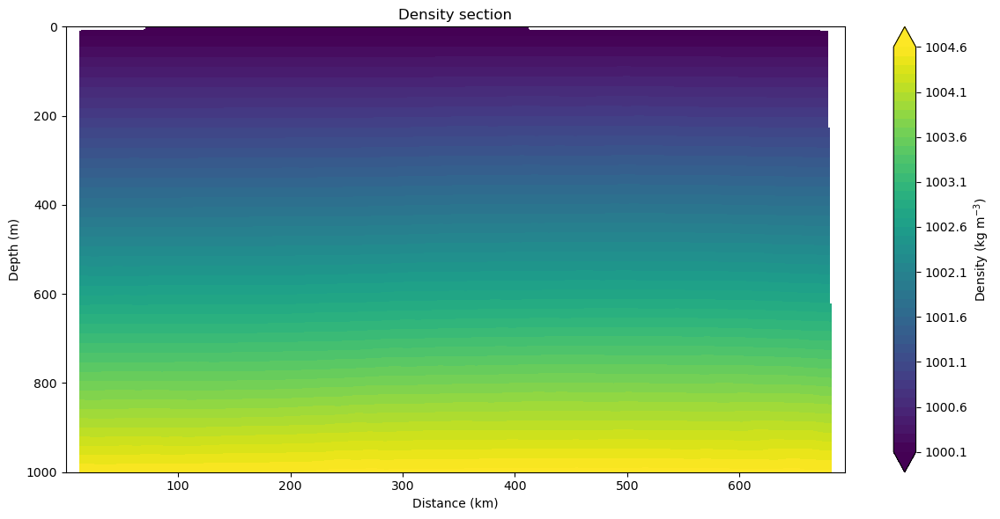

In [53]:
fig, ax = plt.subplots(figsize=(12,6))

# Champ de densité
cf = ax.contourf(
    sigma0.distance,
    sigma0.depth,
    rho - sigma0,
    levels=50,
    cmap="viridis",
    extend="both"
)


cb = plt.colorbar(cf, ax=ax)
cb.set_label(r"Density (kg m$^{-3}$)")

ax.invert_yaxis()
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Depth (m)")
ax.set_title("Density section")

plt.tight_layout()
plt.show()

In [ ]:
# def plot_adcp_swot_map(
#     fig,
#     ax,
#     ds_full,
#     ds_cut,
#     curr_day,
#     lon_swot,
#     lat_swot,
#     ugos_swot,
#     vgos_swot,
#     var,
#     u_adcp,
#     v_adcp,
#     ugos_track,
#     vgos_track,
#     anti,
#     cyc,
#     crs,
#     longs_bato,
#     lat_bato,
#     x_dist,
# ):

#     sc = ax.scatter(
#         lon_swot.flatten(),
#         lat_swot.flatten(),
#         c=var,
#         s=1,
#         cmap="RdBu_r",
#         vmin=-1,
#         vmax=1,
#         transform=ccrs.PlateCarree()
#     )
#     step = 100
#     vecteurs = ax.quiver(
#         lon_swot.flatten()[::step],
#         lat_swot.flatten()[::step],
#         ugos_swot.flatten()[::step],
#         vgos_swot.flatten()[::step],
#         color="black",
#         scale=5.e1,
#         width=0.002,
#         transform=ccrs.PlateCarree()
#     )

#     ax.scatter(
#         longs_bato[::50],
#         lat_bato[::50],
#         s=1,
#         color="black",
#         transform=crs,
#         zorder=15,
#     )

#     step = 50

#     # =========================
#     # ADCP vectors
#     # =========================
#     q_adcp = ax.quiver(
#         curr_day.lon_adcp.values[::step],
#         curr_day.lat_adcp.values[::step],
#         u_adcp[::step],
#         v_adcp[::step],
#         transform=crs,
#         scale=3,
#         width=0.005,
#         color="blueviolet",
#         zorder=100,
#     )

#     # =========================
#     # Satellite vectors
#     # =========================
#     q_sat = ax.quiver(
#         curr_day.lon_adcp.values[::step],
#         curr_day.lat_adcp.values[::step],
#         ugos_track.values[::step],
#         vgos_track.values[::step],
#         transform=crs,
#         scale=3,
#         width=0.005,
#         color="orange",
#         zorder=100,
#     )

#     # =========================
#     # 🔥 DISTANCE LABELS (NEW)
#     # =========================
#     target_dists = np.arange(50, np.nanmax(x_dist)/1000, 50)  # km

#     x_km = x_dist / 1000
#     lon = curr_day.lon_adcp.values
#     lat = curr_day.lat_adcp.values

#     for d in target_dists:
#         idx = np.argmin(np.abs(x_km - d))

#         ax.text(
#             lon[idx],
#             lat[idx],
#             f"{int(d)} km",
#             transform=crs,
#             fontsize=3,
#             color="black",
#             ha="left",
#             va="bottom",
#             bbox=dict(
#                 boxstyle="round,pad=0.2",
#                 facecolor="white",
#                 edgecolor="black",
#                 linewidth=0.2,
#                 alpha=0.8,
#             ),
#             zorder=120,
#         )

   
#        # -----------------------------
#     # DATE (PROPRE, SANS IDX)
#     # -----------------------------
#     t = pd.to_datetime(ds_cut.time.values)
#     t_valid = t[~pd.isna(t)]
#     first_time = t_valid[0]
#     first_time = first_time.strftime("%d %b %H:%M")

#     # -----------------------------
#     # POSITION DEBUT TRACK (ZONE)
#     # -----------------------------
#     mask = (
#         (ds_full.longitude.values >= lon_min) &
#         (ds_full.longitude.values <= lon_max) &
#         (ds_full.latitude.values >= lat_min) &
#         (ds_full.latitude.values <= lat_max)
#     )

#     idx = np.where(mask.flatten())[0]

#     if len(idx) > 0:
#         i0 = idx[0]

#         x0 = ds_full.longitude.values.flatten()[i0]
#         y0 = ds_full.latitude.values.flatten()[i0]

#         ax.text(
#             x0, y0,
#             f"{first_time}",
#             fontsize=8,
#             color="black",
#             transform=ccrs.PlateCarree(),
#             bbox=dict(facecolor="white", alpha=0.6, edgecolor="none")
#         )
#     return fig, ax, sc, q_adcp, 
# gl = ax.gridlines(draw_labels=True)
# gl.top_labels = False
# gl.right_labels = False

# # -----------------------------
# # COLORBAR (COMMUNE)
# # -----------------------------
# cbar = plt.colorbar(sc, ax=ax, shrink=0.8)
# cbar.set_label("\u03B6 /f" + "[1/s]")

# # -----------------------------
# # TITLE
# # -----------------------------
# # ax.set_title("SWOT L3 (subset + correct time labels)")

# plt.show()

#     # =========================
#     # Reference arrow
#     # =========================
#     ax.quiverkey(
#         q_adcp,
#         X=1.1,
#         Y=0.9,
#         U=0.2,
#         label="0.2 m/s",
#         fontproperties={"size": 8},
#         labelpos="E",
#         color="black"
#     )


#     # =========================
#     # Legend
#     # =========================
#     from matplotlib.lines import Line2D

#     legend_handles = [
#         Line2D([0], [0], color="blueviolet", lw=2, label="ADCP"),
#         Line2D([0], [0], color="orange", lw=2, label="Satellite"),
#     ]

#     leg = ax.legend(
#         handles=legend_handles,
#         loc="upper right",
#         fontsize="small",
#         frameon=True,
#     )
#     leg.set_zorder(110)

#     return fig, ax